# Bets e saúde mental: jogo patológico (F63) nos CAPS

**Pergunta:** o boom das apostas aumentou a procura por tratamento de jogo patológico na rede pública?

**Por que este outcome é diferente dos outros.** Inadimplência e consumo mudam por mil motivos (juros, emprego,
inflação), por isso nos painéis precisamos de efeito fixo de mês, que joga fora o efeito nacional. O **CID F63**
(transtornos dos hábitos e dos impulsos, que inclui **F63.0, jogo patológico**) é quase **específico de apostas**.
Isso permite ler a própria **tendência nacional** como evidência, coisa que não dava para fazer com a inadimplência.

**Fonte:** SIA-PS (RAAS, Registro das Ações Ambulatoriais de Saúde Psicossocial), produção dos CAPS no SUS.
Dados: `uv run python -m src.saude_mental.sia_caps` (todas as UFs, 2018 em diante). Os arquivos `.dbc` são
baixados direto do FTP do DATASUS, em paralelo. O pysus não aceita vários processos ao mesmo tempo, e conferimos
que o agregado sai idêntico ao do pysus.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import pyfixest as pf
from scipy import stats

from src.config import CHOQUES, COPAS, INTERIM, PANDEMIA, PROCESSED
from src.painel import estimar, painel

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)


def marcar(ax, desde="2018-01-01"):
    ini, fim = pl.Series(PANDEMIA).str.to_date()
    ax.axvspan(ini, fim, color="gray", alpha=0.15, lw=0)
    for rot, (a, b) in COPAS.items():
        a, b = pl.Series([a, b]).str.to_date()
        ax.axvspan(a, b, color="goldenrod", alpha=0.25, lw=0)
    for d, rot in CHOQUES.items():
        if d >= desde:
            x = pl.Series([d]).str.to_date()[0]
            ax.axvline(x, color="crimson", ls="--", lw=0.8, alpha=0.7)
            ax.text(x, 1.0, " " + rot, rotation=90, va="top", ha="right", fontsize=7, color="crimson", transform=ax.get_xaxis_transform())

## Como ler os gráficos

Mesma convenção dos outros notebooks: as **linhas vermelhas** são os marcos regulatórios (Lei 13.756/2018, Lei 14.790/2023,
bloqueio de out/2024, mercado regulado em jan/2025, MP 1.394 em set/2026), a **faixa cinza** é a pandemia
(mar/2020–dez/2021) e as **faixas douradas** são as Copas do Mundo.

## Decisões

**Unidade de contagem.** Uma RAAS é, grosso modo, um registro mensal de um paciente em acompanhamento num CAPS. Usamos:
- `raas_f63`: RAAS com **CID principal** em F63 (todos os subcódigos; o SUS frequentemente registra só 3 caracteres);
- `raas_mental`: RAAS com CID principal no capítulo F inteiro (denominador);
- `pacientes_f63`: pacientes distintos (CNS) com F63 no mês, contados dentro de cada arquivo UF × mês.

**Medida principal: F63 por mil RAAS de saúde mental.** Usar a participação, e não a contagem, neutraliza três coisas
que mexem no volume total dos CAPS sem relação com apostas: a pandemia (atendimento caiu em 2020), a expansão da rede
(novos CAPS) e mudanças na digitação da produção. O que sobra é a **composição** da demanda: de cada mil pacientes de
saúde mental, quantos são por jogo patológico.

**Geografia.** Os arquivos são por UF do CAPS. Agregamos pelo **município de residência do paciente** (`MUNPAC`, 6
dígitos), e a UF vem dos 2 primeiros dígitos. Pacientes atendidos fora da UF contam na UF onde moram.

**Início da série.** O mês de cada registro vem da **data de atendimento** (`DT_ATEND`), não do mês do arquivo.
Os arquivos de 2018 trazem alguns atendimentos de 2017, enviados com atraso. Esses meses ficam incompletos e são
descartados: a série começa em **jan/2018**.

**Último mês.** O DATASUS publica com defasagem, e os meses mais recentes podem estar incompletos (CAPS que ainda não
enviaram a produção). Os **2 últimos meses disponíveis são descartados**.

**Ameaça principal: codificação.** O Plano de Ação do GT Interministerial (Fazenda, Saúde, Esporte, Secom, 2025)
previu a **capacitação da RAPS** para atender jogo problemático. Profissionais capacitados podem passar a registrar
F63 com mais frequência, sem aumento real de casos. Testamos isso na seção 3.

In [2]:
arquivos = sorted((INTERIM / "sia").glob("PS*.parquet"))
ufs_baixadas = sorted({a.stem[2:4] for a in arquivos})
print(f"{len(arquivos)} arquivos, {len(ufs_baixadas)} UFs: {' '.join(ufs_baixadas)}")
sia = pl.concat([pl.read_parquet(a) for a in arquivos], how="diagonal_relaxed")
sia = sia.with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data"), pl.col("cod_mun6").str.slice(0, 2).alias("cod_uf"))
meses = sorted(sia["data"].unique())
corte = meses[-3]  # descarta os 2 últimos meses (incompletos)
# a competência vem da data de atendimento: arquivos de 2018 trazem alguns atendimentos de 2017 (envio atrasado)
sia = sia.filter(pl.col("data").is_between(pl.date(2018, 1, 1), corte))
print("período:", sia["data"].min(), "a", sia["data"].max())

2807 arquivos, 27 UFs: AC AL AM AP BA CE DF ES GO MA MG MS MT PA PB PE PI PR RJ RN RO RR RS SC SE SP TO


período: 2018-01-01 a 2026-06-01


## 1. Tendência nacional

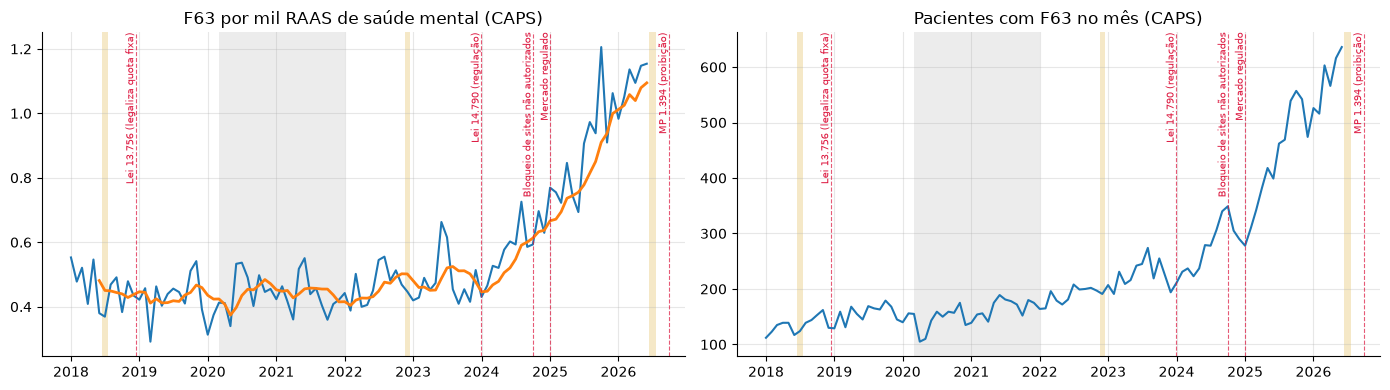

In [3]:
nac = (sia.group_by("data").agg(pl.col("raas_total", "raas_mental", "raas_f63", "raas_subst", "pacientes_f63").sum())
       .with_columns((pl.col("raas_f63") / pl.col("raas_mental") * 1000).alias("f63_por_mil")).sort("data"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(nac["data"], nac["f63_por_mil"]); axes[0].plot(nac["data"], nac["f63_por_mil"].rolling_mean(6), lw=2)
axes[0].set_title("F63 por mil RAAS de saúde mental (CAPS)")
axes[1].plot(nac["data"], nac["pacientes_f63"]); axes[1].set_title("Pacientes com F63 no mês (CAPS)")
for ax in axes: marcar(ax)
plt.tight_layout()

In [4]:
anual = (nac.with_columns(pl.col("data").dt.year().alias("ano")).group_by("ano")
         .agg(pl.col("raas_f63", "raas_mental").sum(), pl.col("pacientes_f63").mean().alias("pacientes_f63_mes"),
              pl.len().alias("meses"))
         .with_columns((pl.col("raas_f63") / pl.col("raas_mental") * 1000).alias("f63_por_mil")).sort("ano"))
anual.to_pandas().set_index("ano")

,raas_f63,raas_mental,pacientes_f63_mes,meses,f63_por_mil
ano,,,,,
2018,5543,12109778,134.750,12,0.458
2019,6197,14102012,156.333,12,0.439
2020,4243,9856403,145.333,12,0.430
2021,5046,11589220,166.000,12,0.435
2022,6164,13121137,187.833,12,0.470
2023,7784,16123979,225.583,12,0.483
2024,9813,16864539,273.833,12,0.582
2025,16940,19166229,431.000,12,0.884
2026,10100,9199695,577.167,6,1.098


## 2. F63 cresceu mais que o resto da saúde mental?

Índice (média de 2019 = 100) de três grupos: F63, saúde mental total (F) e substâncias (F10–F19). Se a alta do F63
fosse só expansão dos CAPS ou recuperação da pandemia, os três subiriam juntos.

**Decisão — base 2019:** último ano completo antes da pandemia e antes do boom das bets (que começa em 2020–21).

Text(0.5, 1.0, 'RAAS por grupo de CID, média móvel 3 meses (2019 = 100)')

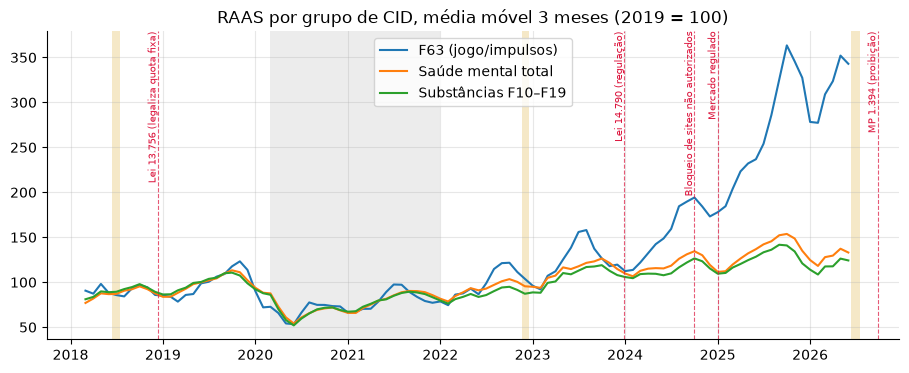

In [5]:
base = nac.filter(pl.col("data").dt.year() == 2019).select(pl.col("raas_f63", "raas_mental", "raas_subst").mean())
idx = nac.with_columns([(pl.col(c) / base[c][0] * 100).alias(c + "_idx") for c in ["raas_f63", "raas_mental", "raas_subst"]])
fig, ax = plt.subplots()
for c, rot in [("raas_f63_idx", "F63 (jogo/impulsos)"), ("raas_mental_idx", "Saúde mental total"), ("raas_subst_idx", "Substâncias F10–F19")]:
    ax.plot(idx["data"], idx[c].rolling_mean(3), label=rot)
marcar(ax); ax.legend(); ax.set_title("RAAS por grupo de CID, média móvel 3 meses (2019 = 100)")

## 3. Teste de codificação

Se a alta do F63 viesse de os profissionais passarem a **registrar** melhor, ela apareceria como um **degrau**
depois da capacitação, e não acompanharia o interesse por apostas. Comparamos a série nacional de F63 por mil com o
Google Trends nacional: se as duas sobem e caem juntas (incluindo a **queda** das buscas depois de 2023), isso
favorece demanda real. Uma melhora de registro não "desfaz" quando as buscas caem.

correlação F63 por mil × Trends defasado  0 meses: +0.28
correlação F63 por mil × Trends defasado  6 meses: +0.34
correlação F63 por mil × Trends defasado 12 meses: +0.46


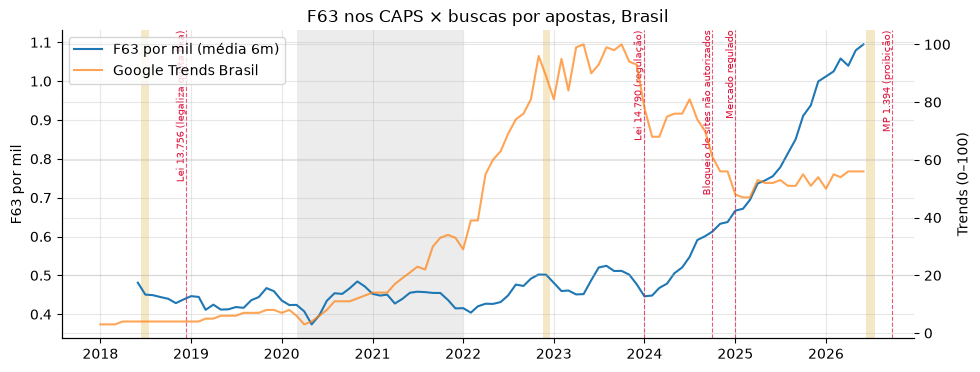

In [6]:
gt = pl.read_parquet(PROCESSED / "google_trends_uf.parquet").filter(pl.col("uf") == "BR").select("data", pl.col("indice").alias("trends_br"))
comp = nac.join(gt, on="data", how="inner")
fig, ax = plt.subplots()
ax.plot(comp["data"], comp["f63_por_mil"].rolling_mean(6), label="F63 por mil (média 6m)", color="C0")
ax2 = ax.twinx(); ax2.plot(comp["data"], comp["trends_br"], label="Google Trends Brasil", color="C1", alpha=0.7)
ax.set_ylabel("F63 por mil"); ax2.set_ylabel("Trends (0–100)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left")
marcar(ax); ax.set_title("F63 nos CAPS × buscas por apostas, Brasil")
for k in (0, 6, 12):
    r = comp.select(pl.corr(pl.col("f63_por_mil"), pl.col("trends_br").shift(k)))[0, 0]
    print(f"correlação F63 por mil × Trends defasado {k:>2} meses: {r:+.2f}")

⚠ **Correlação entre duas séries com tendência** é fraca como evidência (as duas podem só crescer juntas). O que
informa é o **formato**: se o F63 continua subindo depois de 2023, enquanto o Trends cai, a ligação direta busca →
tratamento fica fraca, e a explicação de codificação ou de defasagem longa (vício leva anos para virar tratamento)
ganha peso.

## 4. Painel UF × mês

Mesmo desenho dos outros painéis, com o outcome **F63 por mil RAAS de saúde mental**, jan/2022 a último mês disponível.

**Decisão — defasagem:** a procura por tratamento vem depois de meses de problema. A especificação principal é
**k = 6** (a mesma do painel de inadimplência), fixada antes de rodar. Reportamos também 0, 3 e 9.

**Decisão — contagens pequenas:** em UFs pequenas, o F63 é zero em muitos meses. A razão por mil é ruidosa lá, então
reportamos também uma **Poisson** (PPML) com a contagem de F63 e log(RAAS de saúde mental) como controle, que lida bem
com zeros. A Poisson não tem wild bootstrap no `pyfixest`; fica só o EP clusterizado.

In [7]:
uf_cod = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA", "22": "PI", "23": "CE",
          "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA", "31": "MG", "32": "ES", "33": "RJ", "35": "SP",
          "41": "PR", "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
por_uf = (sia.with_columns(pl.col("cod_uf").replace_strict(uf_cod, default=None).alias("uf")).drop_nulls("uf")
          .group_by("uf", "data").agg(pl.col("raas_f63", "raas_mental").sum())
          .with_columns((pl.col("raas_f63") / pl.col("raas_mental") * 1000).alias("f63_por_mil"),
                        pl.col("raas_mental").log().alias("log_mental")))
d = painel(por_uf, fim=str(corte)).to_pandas()
print(f"{d['uf'].nunique()} UFs × {d['mes'].nunique()} meses = {len(d)} obs")
res = pd.DataFrame([estimar(d, y="f63_por_mil", x=f"trends_l{k}", rotulo=f"F63 por mil, k = {k}") for k in (0, 3, 6, 9)]).set_index("modelo")
res

27 UFs × 54 meses = 1457 obs


,β,ep,p,p_boot,n
modelo,,,,,
"F63 por mil, k = 0",-0.124,0.111,0.276,0.312,1457
"F63 por mil, k = 3",-0.055,0.076,0.479,0.478,1457
"F63 por mil, k = 6",0.048,0.084,0.573,0.582,1457
"F63 por mil, k = 9",0.018,0.073,0.805,0.813,1457


In [8]:
linhas = []
for k in (0, 3, 6, 9):
    fit = pf.fepois(f"raas_f63 ~ trends_l{k} + log_mental + selic_x_pobreza | uf + mes", data=d.dropna(subset=[f"trends_l{k}"]), vcov={"CRV1": "uf_id"})
    t = fit.tidy().loc[f"trends_l{k}"]
    linhas.append({"modelo": f"Poisson, k = {k}", "β": t["Estimate"], "ep": t["Std. Error"], "p": t["Pr(>|t|)"]})
pd.DataFrame(linhas).set_index("modelo")

,β,ep,p
modelo,,,
"Poisson, k = 0",-0.210,0.274,0.444
"Poisson, k = 3",-0.078,0.158,0.620
"Poisson, k = 6",0.221,0.097,0.022
"Poisson, k = 9",0.186,0.096,0.053


Na Poisson, β é a variação **proporcional** (≈ `exp(β) − 1`) da contagem de F63 para 1 DP de Trends.

## 5. Diferença longa: as UFs que mais apostavam no pico tiveram mais alta depois?

O painel mensal compara mês a mês. Mas, se o caminho aposta → vício → tratamento leva **anos**, o teste certo é de
prazo longo: a exposição no **pico do boom (2023)** prevê a alta do F63 entre **2022–23** e **jul/2025–jun/2026**?

**Decisão — janelas:** o pré são os 24 meses de 2022–23 (pós-pandemia, antes da rampa). O pós são os 12 meses mais
recentes disponíveis. Usamos 12 meses, e não um só, por causa das contagens pequenas.
**Medidas de exposição:** Trends médio de 2023 (nível no pico), crescimento do Trends de 2020 a 2023, e a % que
apostou no DataSenado (jun/2024). Com 27 UFs, reportamos Spearman.

In [9]:
def f63_pm(ini, fim):
    return (sia.with_columns(pl.col("cod_uf").replace_strict(uf_cod, default=None).alias("uf")).drop_nulls("uf")
            .filter(pl.col("data").is_between(pl.date(*ini, 1), pl.date(*fim, 1))).group_by("uf")
            .agg((pl.col("raas_f63").sum() / pl.col("raas_mental").sum() * 1000).alias("x")))

gt_uf = pl.read_parquet(PROCESSED / "google_trends_uf.parquet").filter(pl.col("uf") != "BR")
ano = lambda a: pl.col("indice_comparavel").filter(pl.col("data").dt.year() == a).mean()
expo = gt_uf.group_by("uf").agg(ano(2023).alias("trends_2023"), (ano(2023) - ano(2020)).alias("trends_cresc_20_23"))
ds = pl.read_parquet(PROCESSED / "datasenado_uf_2024.parquet").select("uf", "pct_apostou")
ld = (f63_pm((2022, 1), (2023, 12)).rename({"x": "f63_pre"}).join(f63_pm((2025, 7), (2026, 6)).rename({"x": "f63_pos"}), on="uf")
      .join(expo, on="uf").join(ds, on="uf").with_columns((pl.col("f63_pos") - pl.col("f63_pre")).alias("alta_f63")))
linhas = []
for x in ["trends_2023", "trends_cresc_20_23", "pct_apostou"]:
    r, p = stats.spearmanr(ld[x], ld["alta_f63"])
    linhas.append({"exposição": x, "spearman com a alta do F63": r, "p": p})
display(pd.DataFrame(linhas).set_index("exposição"))
ld.sort("alta_f63", descending=True).to_pandas().set_index("uf").head(10)

,spearman com a alta do F63,p
exposição,,
trends_2023,0.012,0.952
trends_cresc_20_23,0.053,0.792
pct_apostou,0.229,0.250


,f63_pre,f63_pos,trends_2023,trends_cresc_20_23,pct_apostou,alta_f63
uf,,,,,,
AM,0.271,2.127,215.837,202.060,14.000,1.856
RO,0.487,2.303,108.159,91.721,14.000,1.817
MA,0.339,2.103,164.481,138.109,14.000,1.764
PA,0.324,1.802,137.599,124.513,17.000,1.478
MT,0.502,1.651,154.877,142.437,17.000,1.148
RJ,0.274,1.236,184.673,175.788,12.000,0.962
AL,0.195,1.095,116.923,98.695,15.000,0.901
PR,0.576,1.339,75.997,71.199,12.000,0.762
CE,0.461,1.199,118.942,99.136,8.000,0.738


## Leitura

**1. Houve uma alta grande e recente do jogo patológico nos CAPS.** O F63 ficou estável em ~0,44–0,48 por mil RAAS
de saúde mental de 2018 a 2023, e então subiu: ~0,58 em 2024, ~0,88 em 2025 e ~1,1 no 1º semestre de 2026. Os
pacientes com F63 por mês passaram de ~190 (2022) para ~580 (2026). A alta é **específica**: de 2019 para 2025, as RAAS
de F63 cresceram 2,7×, contra 1,4× da saúde mental total e 1,3× de substâncias (seção 2). Então não é expansão da
rede nem recuperação da pandemia.

**2. O formato não é o que se esperaria se o tratamento acompanhasse as apostas de perto.** Durante o boom
(2021–23), quando as buscas por apostas multiplicaram por ~10, o F63 nos CAPS **não se mexeu**. A rampa começa em
meados de 2024, cerca de um ano depois do pico das buscas, e **acelera em 2025–26, enquanto as buscas caem**. É uma
rampa gradual, não um degrau.

**3. A alta não foi maior onde se apostava mais.** No painel mensal, a especificação principal (F63 por mil, k = 6) é
nula. A Poisson com k = 6 dá β ≈ 0,22 (p ≈ 0,02), mas é 1 resultado significativo em 8 especificações, sem wild
bootstrap, e puxado pelas UFs grandes. Isso é frágil. Na diferença longa (seção 5), a exposição no pico não prevê
a alta do F63 (Spearman entre 0,0 e 0,2, sem significância). Entre as maiores altas há UFs muito expostas (AM, MA, RJ), mas também
RO e PR, com exposição baixa, e RR, uma das UFs com mais apostadores no DataSenado, não está entre as 10 maiores.

**Duas explicações compatíveis com 1–3, que os dados ainda não separam:**
- **(a) Fator nacional de reconhecimento e registro.** A partir de 2024, com a CPI das Bets e a cobertura da imprensa,
  e em 2025, com a regulação (avisos de "jogo responsável", autoexclusão centralizada, Plano de Ação do GT
  Interministerial com capacitação da RAPS e protocolo de atendimento), mais gente procura ajuda e mais profissionais
  registram F63. Isso explica uma alta **nacional, gradual e sem relação com a intensidade local de apostas**, e
  explica por que ela acelera quando as buscas caem.
- **(b) Defasagem longa e dano difuso.** O vício leva anos para virar procura por tratamento, e a exposição relevante
  é nacional (publicidade, patrocínio no futebol), então as diferenças entre UFs no Trends pouco importam.

As duas são **más notícias de jeitos diferentes**: (a) diz que havia demanda reprimida e não registrada durante o boom;
(b) diz que o dano das apostas está chegando ao SUS agora.

**Como separar (próximos passos):**
1. **Datar a capacitação da RAPS e o protocolo de atendimento** (Ministério da Saúde) e ver se a rampa tem quebra
   nessas datas. A cronologia das políticas de 2024–25 é o que falta.
2. **Composição dos pacientes F63:** se a alta vem de **pacientes novos** (primeira RAAS) ou de quem já estava no CAPS
   com outro CID e passou a ter F63 registrado. Reclassificação é sinal de (a). O CNS permite seguir o paciente.
3. **SIH (internações) e SIM (suicídio):** são menos sensíveis a mudanças de registro ambulatorial.
4. **Depois da MP 1.394:** se (b) for verdade, a procura deveria continuar alta por muito tempo, porque o vício já
   formado não some com a proibição. Se for (a), ela depende das políticas, não da oferta de apostas.